4. Salvarea dataset-ului : am incarcat un dataset gasit pe kaggle si am extras doar anumite coloane (la inceput erau 77 de coloane iar eu am extras 16 care mi s-au parut cele mai relevante). Am extras datasetul, si am facut cleaning.

In [1]:
import pandas as pd

# am incarcat dataset-ul pe care l-am gasit de pe internet si am extras doar coloanele care ma interesau
df = pd.read_csv('fifa21 raw data v2.csv')

columns = [ 'Name', 'Nationality', '↓OVA','Age', 'POT', 'Positions', 
            'Height', 'Weight', 'Value', 'PAC', 'SHO', 'PAS', 
            'DRI', 'DEF', 'PHY' ]

# pastrez doar coloanele din lista de mai sus
df = df[columns]

# am salvat noul dataset intr-un fisier nou csv
df.to_csv('fifa_dataset.csv', index=False)

df = pd.read_csv('fifa_dataset.csv')

# functii de convertire la int
def convert_height(val):
    if 'cm' in val:
        # daca e in cm, scot textul si convertesc la int
        return float(val.replace('cm', ''))/100
    elif "'" in val:
        # daca e in feet si inchi atunci convertesc la cm
        parts = val.split("'") 
        feet = int(parts[0])
        inch = int(parts[1].replace('"', ''))
        # aplic o rotunjire
        inaltime_cm = round((feet * 30.48) + (inch * 2.54))
        return float(inaltime_cm)/100
    return val

def convert_weight(val):
    # daca e in kg, scot textul si convertesc la int
    if 'kg' in val:
        return int(val.replace('kg', ''))
    elif 'lbs' in val:
        # daca e in pounds, scot textul convertesc la int si schimb in kg
        lbs = int(val.replace('lbs', ''))
        # aplic o rotunjire
        greutate_kg = round(lbs * 0.453592)
        return int(greutate_kg)
    return val

def clean_value(val):
    val = val.replace('€', '')
    if 'M' in val:
        return float(val.replace('M', '')) * 1000000
    elif 'K' in val:
        return float(val.replace('K', '')) * 1000
    else:
        return float(val)
    return val

# aplic functiile de convertire pe coloanele de inaltime, greutate si value
df['Height'] = df['Height'].apply(convert_height)
df['Weight'] = df['Weight'].apply(convert_weight)
df['Value'] = df['Value'].apply(clean_value)

# imi creez o coloana noua Body Mass Index = weight(kg)/height(m)^2
df['BMI'] = df['Weight'] / ((df['Height']) ** 2)

print(df[['Name', 'Height', 'Weight', 'BMI','Value']].head())

                Name  Height  Weight        BMI        Value
0           L. Messi    1.70      72  24.913495  103500000.0
1  Cristiano Ronaldo    1.87      83  23.735308   63000000.0
2           J. Oblak    1.88      87  24.615211  120000000.0
3       K. De Bruyne    1.81      70  21.366869  129000000.0
4          Neymar Jr    1.75      68  22.204082  132000000.0


/var/folders/dj/w75by4xs4y92vhpl1bx72_t40000gn/T/ipykernel_14011/3689140891.py:4: DtypeWarning: Columns (76) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('fifa21 raw data v2.csv')


In urmatoarea casuta am simulat 5% valori random Nan pe coloana PAC.

In [2]:
import numpy as np

# setez un seed pt a genera aceleasi valori
np.random.seed(42)

# 5% din valorile de pe coloana PAC vor deveni 0
procent = 0.05

# imi creez o masca care alege aleatoriu 5% din randuri
mask = np.random.rand(len(df)) < procent

# inlocuiesc valorile cu 0
df.loc[mask, 'PAC'] = np.nan
print(f"Valori lipsa pe coloana PAC: {df['PAC'].isna().sum()}\n")

df.to_csv('fifa_dataset_curatat.csv', index=False)


Valori lipsa pe coloana PAC: 941



2. Am impartit datasetul in 2 subset-uri: unul de train si unul de test, prin extragere randomizata.

In [3]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df, test_size = 0.2, random_state = 42)

print(f"Dimensiunea setului de antrenament: {df_train.shape}")
print(f"Dimensiunea setului de test: {df_test.shape}")

df_train.to_csv('fifa_train.csv', index = False)
df_test.to_csv('fifa_test.csv', index = False)


Dimensiunea setului de antrenament: (15183, 16)
Dimensiunea setului de test: (3796, 16)


6. a. Am afisat numarul si procentul pe coloana a valorilor lipsa.

In [4]:
# numarul de valori lipsa pe fiecare coloana
val_lipsa_train = df_train.isnull().sum()
val_lipsa_test = df_test.isnull().sum()
# calculez procentul
val_lipsa_procent_train = (df_train.isnull().sum() / len(df_train)) * 100
val_lipsa_procent_test = (df_test.isnull().sum() / len(df_test)) * 100

# le afisez tabelar
print(pd.DataFrame({'Numar train': val_lipsa_train, 'Procent train': val_lipsa_procent_train, 
                    'Numar test': val_lipsa_test, 'Procent test': val_lipsa_procent_test}))


             Numar train  Procent train  Numar test  Procent test
Name                   0       0.000000           0      0.000000
Nationality            0       0.000000           0      0.000000
↓OVA                   0       0.000000           0      0.000000
Age                    0       0.000000           0      0.000000
POT                    0       0.000000           0      0.000000
Positions              0       0.000000           0      0.000000
Height                 0       0.000000           0      0.000000
Weight                 0       0.000000           0      0.000000
Value                  0       0.000000           0      0.000000
PAC                  759       4.999012         182      4.794521
SHO                    0       0.000000           0      0.000000
PAS                    0       0.000000           0      0.000000
DRI                    0       0.000000           0      0.000000
DEF                    0       0.000000           0      0.000000
PHY       

Observ ca am 759 de valori lipsa la voloana PAC asa ca le voi imputa cu media de pe coloana. Calculez media cu functia mean() si dupa cu fillna adaug la valorile Nan valoarea dorita. Atat in subset-ul de trai cat si in cel de test voi adauga media din train.

In [5]:
medie_pac_train = df_train['PAC'].mean()

df_train['PAC'] = df_train['PAC'].fillna(medie_pac_train)
df_test['PAC'] = df_test['PAC'].fillna(medie_pac_train)

print(f"Valori lipsa dupa curatare pe coloana PAC in train: {df_train['PAC'].isna().sum()}\n")
print(f"Valori lipsa dupa curatare pe coloana PAC in test: {df_test['PAC'].isna().sum()}\n")

Valori lipsa dupa curatare pe coloana PAC in train: 0

Valori lipsa dupa curatare pe coloana PAC in test: 0



6. b. Cu ajutorul functiei describe am printat tabelele urmatoare care ne ofera informatii legat de numarul de jucatori, minimul sau maximul pentru anumite valori etc. Totodata este implementat si un tabel pentru variabilele categorice cum ar fi Name, Nationality si Positions.

In [6]:
print("Statistici Descriptive")

print("Subset Train")
display(df_train.describe())
display(df_train.describe(include=['object']))
print("Subset Test")
display(df_test.describe())
display(df_test.describe(include=['object']))

Statistici Descriptive
Subset Train


,↓OVA,Age,POT,Height,Weight,Value,PAC,SHO,PAS,DRI,DEF,PHY,BMI
count,15183.000000,15183.000000,15183.000000,15183.000000,15183.000000,1.518300e+04,15183.000000,15183.00000,15183.000000,15183.000000,15183.000000,15183.000000,15183.000000
mean,65.707831,25.162155,71.176118,1.811886,75.006981,2.873556e+06,67.493899,53.50932,57.651913,62.886781,49.775143,64.377066,22.819984
std,6.998174,4.715603,6.126316,0.068356,7.061659,7.693424e+06,10.312575,13.81014,10.080278,9.903029,16.489120,9.624748,1.364843
min,47.000000,16.000000,47.000000,1.550000,50.000000,0.000000e+00,25.000000,17.00000,25.000000,25.000000,12.000000,28.000000,17.358919
25%,61.000000,21.000000,67.000000,1.760000,70.000000,4.750000e+05,62.000000,44.00000,51.000000,57.000000,35.000000,58.000000,21.913806
50%,66.000000,25.000000,71.000000,1.810000,75.000000,9.500000e+05,67.493899,56.00000,58.000000,64.000000,53.000000,65.000000,22.837370
75%,70.000000,28.000000,75.000000,1.860000,80.000000,2.000000e+06,74.000000,64.00000,64.000000,69.000000,63.000000,71.000000,23.671254
max,92.000000,53.000000,95.000000,2.030000,110.000000,1.855000e+08,96.000000,93.00000,93.000000,94.000000,91.000000,91.000000,34.717839


,Name,Nationality,Positions
count,15183,15183,15183
unique,14461,157,593
top,J. Rodríguez,England,CB
freq,11,1370,1937


Subset Test


,↓OVA,Age,POT,Height,Weight,Value,PAC,SHO,PAS,DRI,DEF,PHY,BMI
count,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3.796000e+03,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000,3796.000000
mean,65.761855,25.321918,70.977608,1.812466,75.067176,2.831095e+06,67.363248,53.247893,57.797418,62.827977,50.230506,64.336407,22.821907
std,6.851804,4.688579,6.065890,0.068584,7.121603,7.652906e+06,10.844384,13.896206,10.088661,10.025536,16.255351,9.511070,1.357596
min,47.000000,16.000000,48.000000,1.590000,53.000000,0.000000e+00,28.000000,16.000000,25.000000,27.000000,15.000000,31.000000,17.961266
25%,61.750000,22.000000,67.000000,1.760000,70.000000,4.750000e+05,62.000000,43.000000,51.000000,57.000000,35.000000,58.000000,21.913806
50%,66.000000,25.000000,71.000000,1.810000,75.000000,9.500000e+05,67.493899,56.000000,59.000000,64.000000,54.000000,65.500000,22.839506
75%,70.000000,29.000000,75.000000,1.860000,80.000000,2.000000e+06,74.000000,64.000000,65.000000,69.000000,63.000000,71.000000,23.666910
max,93.000000,43.000000,93.000000,2.060000,107.000000,1.290000e+08,96.000000,92.000000,93.000000,95.000000,87.000000,88.000000,29.761905


,Name,Nationality,Positions
count,3796,3796,3796
unique,3743,129,345
top,J. García,England,CB
freq,4,335,504


6. c. Analiza distributiei variabilelor - Am folosit histograme pentru caracteristicile numerice si countplot-uri pentru variabilele categorige. La countplot-uri am selectat doar top 10 pentru a nu inghesui graficele. (Name nu este o categorie relevanta pentru un astfel de grafic)

Histograme pentru caracteristicile numerice


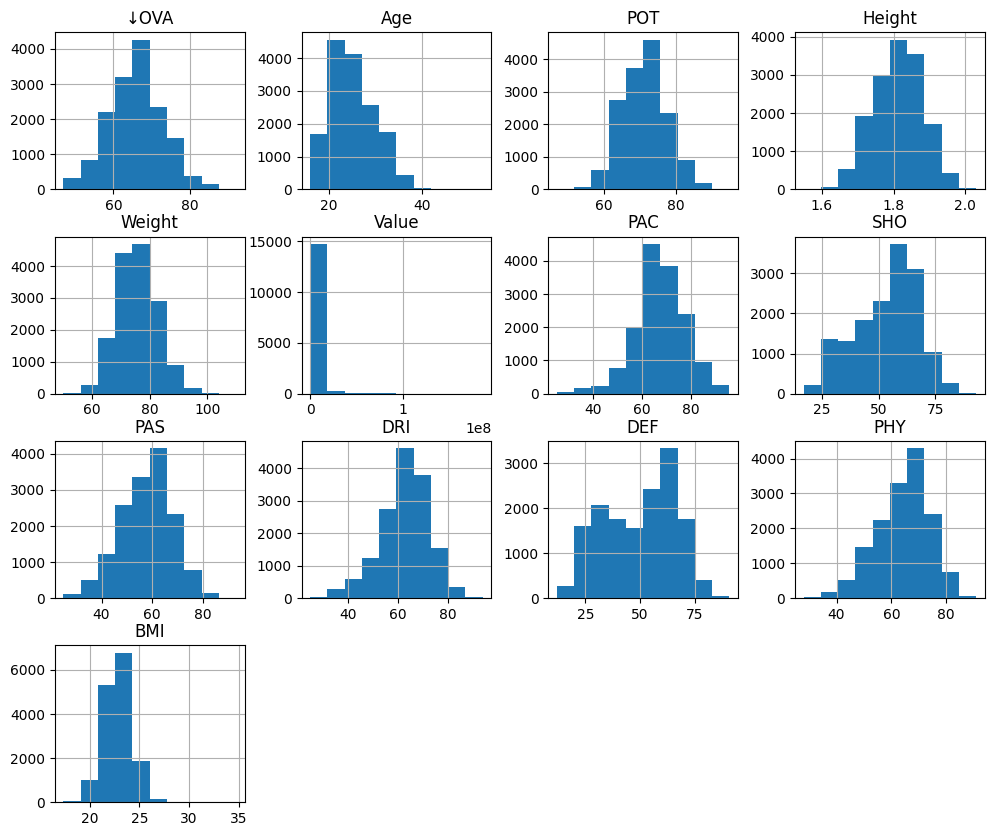

Barplot pentru Top 10 Nationalities


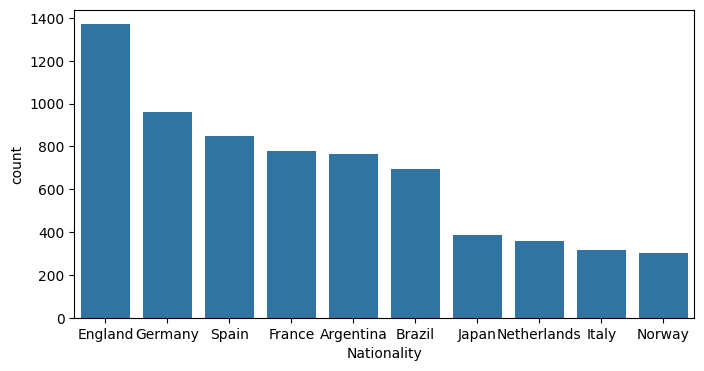

Barplot pentru Top 10 Positions


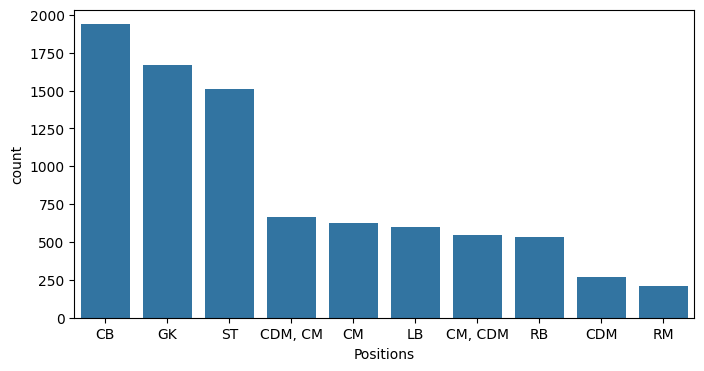

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograme
print("Histograme pentru caracteristicile numerice")
df_train.hist(figsize=(12, 10))
plt.show()

# Countplot
print("Barplot pentru Top 10 Nationalities")
plt.figure(figsize=(8, 4))

# imi selectez cele mai populare 10 tari
top_10_tari = df_train['Nationality'].value_counts().head(10).index
sns.countplot(x='Nationality', data=df_train, order=top_10_tari)
plt.show()

print("Barplot pentru Top 10 Positions")
plt.figure(figsize=(8, 4))

top_10_pozitii = df_train['Positions'].value_counts().head(10).index
sns.countplot(x='Positions', data=df_train, order=top_10_pozitii)
plt.show()


Ce observam? 
- Din histograme observam ca majoritatea variabilelor, de exemplu Age, OVA si PAC, au o distributie aproximativ normala. In schimb Value are o distributie extrem de asimetrica, ceea ce inseamna ca majoritatea jucatorilor au o valoarea mica, in timp ce un numar de jucatori au valori foarte mari. Din countplot-uri se observa ca Anglia are cei mai multi jucatori, iar pozitia CB este cea mai frecventa.

Ce suspiciuni/idei putem formula? 
- Distributia proasta a lui Value poate sa ne dea suspiciunea ca modelul de regresie ar putea fi influentat de acei putini jucatori foarte scumpi.

Ce preprocesari ar trebui sa aplicam?
- O preprocesare buna ar fi transformarea coloanei Value intr-o distributie mai normala pentru a ajuta modelul sa faca predictii mai precise.

6. d. Detectarea outlierilor - am folosit boxplot-uri pentru cele mai semnificative coloane : Age, Value, OVA.

Detectarea Outlierilor


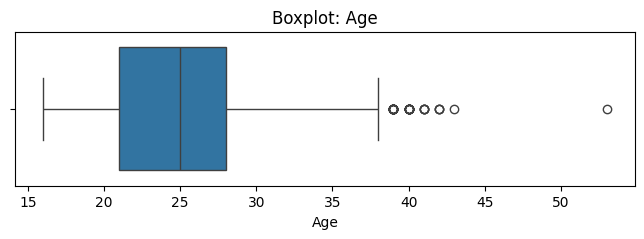

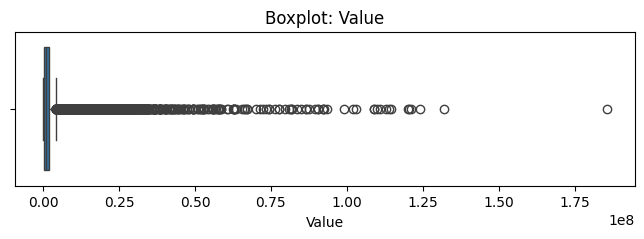

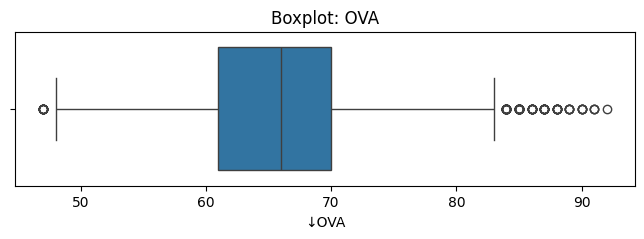

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Detectarea Outlierilor")

plt.figure(figsize=(8, 2))
sns.boxplot(x=df_train['Age'])
plt.title('Boxplot: Age')
plt.show()

plt.figure(figsize=(8, 2))
sns.boxplot(x=df_train['Value'])
plt.title('Boxplot: Value')
plt.show()

plt.figure(figsize=(8, 2))
sns.boxplot(x=df_train['↓OVA'])
plt.title('Boxplot: OVA')
plt.show()


Ce observam?
- Din boxplot-uri se observa ca avem outlieri la toate cele 3 categorii. La Age se observa cativa veterani(jucatorii de peste 40 de ani) care apar ca puncte pe grafic. La OVA, avem outlieri din partea dreapta care au rating de peste 85 rating. La Value se observa jucatorii cei mai scumpi cu preturi de peste 50-100 de milioane de euro.

Ce suspiciuni/idei putem formula?
- Acesti outlieri nu sunt erori de date ci jucatori reali, dar care reprezinta un risc pentru modelul de regresie liniara care urmeaza a fi implementat.

Ce preprocesari ar trebui sa aplicam?
- O preprocesare buna consider ca ar fi utilizarea unui model de regresie cat mai bun sau aplicarea unei transformari pentru o distributie mai normala a categoriei Value (logaritmic de exemplu).

6. e. Analiza corelatiilor - creez un heatmap cu ajutorul functiei .heatmap(). Am folosit doar variabilele numerice, iar variabila tinta este in principiu Value.

Analiza corelatiilor


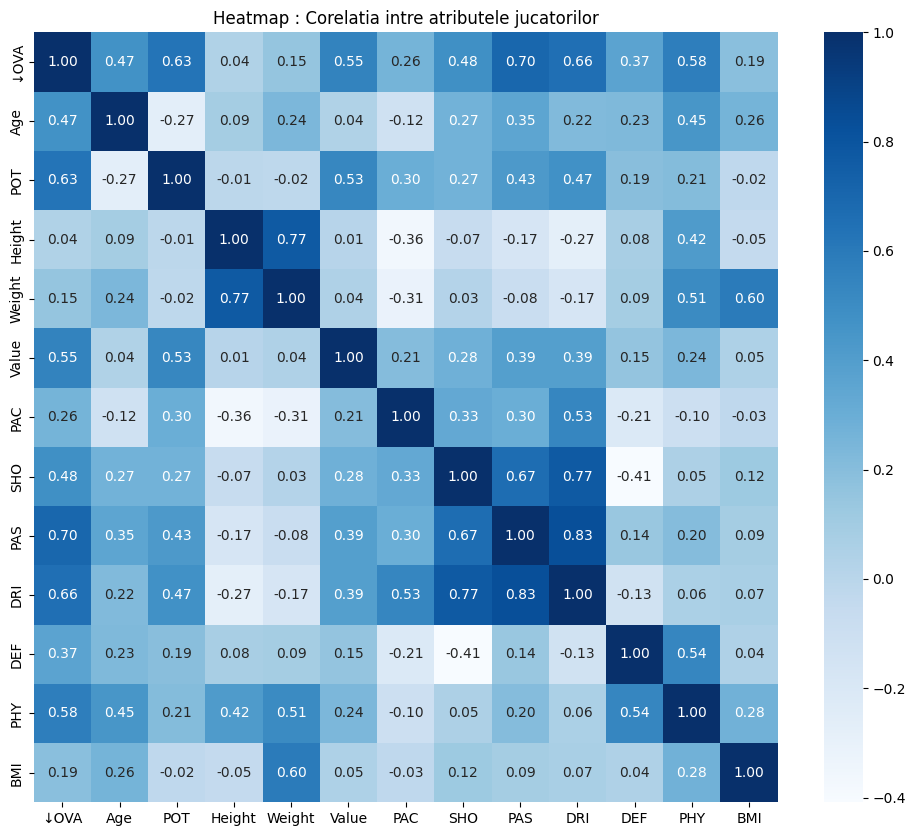

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Analiza corelatiilor")

date_numerice = df_train.select_dtypes(include = ['float64', 'int64'])

matrice_corelatie = date_numerice.corr()

plt.figure(figsize = (12, 10))
sns.heatmap(matrice_corelatie, annot=True, fmt='.2f', cmap='Blues')

plt.title("Heatmap : Corelatia intre atributele jucatorilor")
plt.show()

Ce observam?
- Analizand heatmap-ul, se observa corelatii puternice intre Value si OverallRating(OVA) sau Potential(POT). Totodata, se observa o corelatie negativa intre Age si PAC, asta inseamna ca pe masura ce un jucator imbatraneste, viteza lui scade. Pe de alta parte, se observa faptul ca driblingul(DRI) si passingul(PAS) sunt in corelatie aproape 1 (0.83), indicand faptul ca daca un jucator este bun la una dintre acestea, v-a fi bun si la cealalta.

Ce suspiciuni/idei putem formula?
- Deoarece OVA si POT sunt foarte puternic corelate cu Value, ne asteptam ca modelul nostru sa se bazez foarte mult pe aceste 2 variabile cand va face o predictie. Inca o chestie este faptul ca Height-ul sau BMI-ul unui jucator este in corelatie aproape 0 cu value, indicand ca atributele fizice nu influenteaza pretul lui.

6. f. Analiza relatiilor cu variabila tinta - am folosit scatterplots, iar variabila tinta este Value.

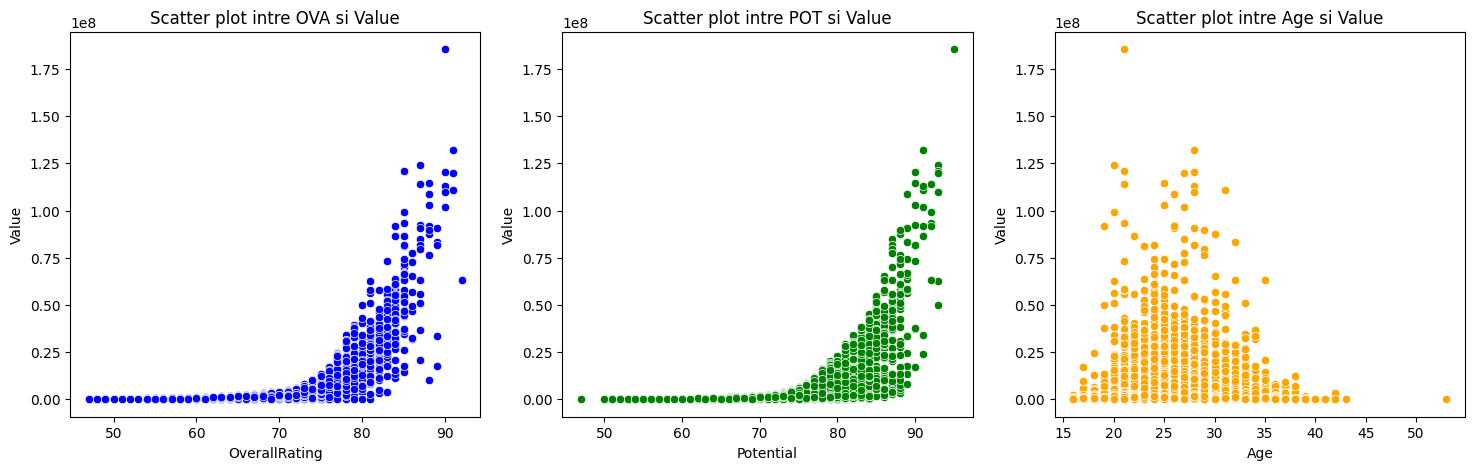

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18,5))

plt.subplot(1,3,1)
sns.scatterplot(x = df_train['↓OVA'], y = df_train['Value'], color = 'blue')
plt.title('Scatter plot intre OVA si Value')
plt.xlabel('OverallRating')
plt.ylabel('Value')

plt.subplot(1,3,2)
sns.scatterplot(x = df_train['POT'], y = df_train['Value'], color = 'green')
plt.title('Scatter plot intre POT si Value')
plt.xlabel('Potential')
plt.ylabel('Value')

plt.subplot(1,3,3)
sns.scatterplot(x = df_train['Age'], y = df_train['Value'], color = 'orange')
plt.title('Scatter plot intre Age si Value')
plt.xlabel('Age')
plt.ylabel('Value')

plt.show()

Ce observam?
- Din primele 2 scatterplot-uri se observa ca doar de la un rating sau potential de peste 80 pretul creste semnificativ. La graficul cu varsta, se observa ca cei mai scumpi jucatori sunt in prime, adica au intre 23 si 29 de ani. Cei tineri sau batrani sunt semnificativ mai ieftini.

Ce suspiciuni/idei putem formula?
- Din cauza ca cresterea este exponentiala la primele 2 grafice, modelul de regresie este posibil sa aiba probleme.

Ce preprocesari ar trebui sa aplicam?
- Aceste grafice confirma ca modelul de regresie ales trebuie sa fie foarte robust.

7. Antrenarea si evaluarea unui model de baza - antrenez modelul pe subsetul de antrenare si il evaluez pe subsetul de testare. Apoi raportez si interpretez rezultatele folosind mean absolut error, mean squared error si r2 score. Apoi creez un scatterplot pentru a compara valorile reale vs valorile prezise.

Mean Absolute Error: 3074416.59 euro
Root Mean Squared Error: 6052494.44 euro
R^2: 0.37


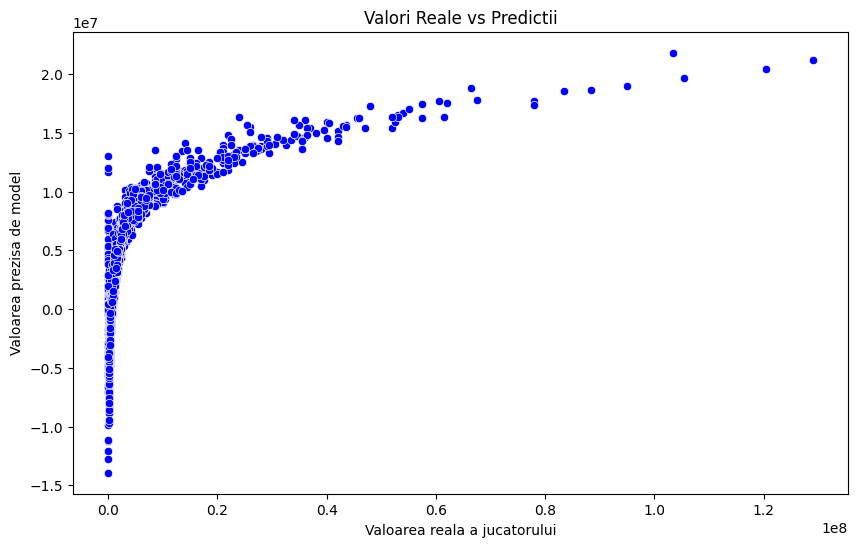

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# am selectat doar atributele care influenteaza valoarea cel mai mult
features = ['Age', '↓OVA', 'POT', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY', 'BMI']

# am pregatit in X_train atributele de care se v-a folosi modelul si tinta, adica Value
# le-am adaugat atat pentru train cat si pentru test
X_train = df_train[features]
y_train = df_train['Value']

X_test = df_test[features]
y_test = df_test['Value']

# initializez modelul si il antrenez
model = LinearRegression()
model.fit(X_train, y_train)

# fac predictii cu date pe care nu le-a mai vaut
y_pred = model.predict(X_test)

# calculez metricile de evaluare
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error: {mae:.2f} euro")
print(f"Root Mean Squared Error: {rmse:.2f} euro")
print(f"R^2: {r2:.2f}")

plt.figure(figsize = (10, 6))
sns.scatterplot(x = y_test, y = y_pred, color = 'blue')

plt.title("Valori Reale vs Predictii")
plt.xlabel("Valoarea reala a jucatorului")
plt.ylabel("Valoarea prezisa de model")
plt.show()